**Plug Flow Reactor (PFR): Steam Methane Reforming in a Packed Bed**

In this tutorial we model steam methane reforming in an isothermal packed bed plug flow reactor, and validate the result against an equivalent DWSIM PFR model (Peng-Robinson property package).

A PFR is discretized along its length: the reaction rate, composition and pressure change continuously from inlet to outlet,

$$\frac{dF_j}{dV} = \nu_j \, r$$

### Reaction and kinetics:

$$\mathrm{CH_4 + H_2O \rightleftharpoons 3\,H_2 + CO} \qquad \Delta H_r(25\,^{\circ}\mathrm{C}) = +205.8\ \mathrm{kJ/mol}$$

The rate per kg of catalyst has the Xu & Froment (1989) form, as entered in the DWSIM model:

$$r = \frac{k}{p_{\mathrm{H_2}}^{2.5}} \, \frac{p_{\mathrm{CH_4}}\,p_{\mathrm{H_2O}} - p_{\mathrm{H_2}}^3\,p_{\mathrm{CO}}/K}{\left(1 + K_{\mathrm{CH_4}}\,p_{\mathrm{CH_4}} + K_{\mathrm{CO}}\,p_{\mathrm{CO}} + K_{\mathrm{H_2}}\,p_{\mathrm{H_2}} + K_{\mathrm{H_2O}}\,p_{\mathrm{H_2O}}/p_{\mathrm{H_2}}\right)^2}$$

with $k = 4.22\times10^{15}\,e^{-240100/RT}$, $K = e^{30.42 - 27106/T}$ and the adsorption constants of the DWSIM model. Partial pressures are in **Pa**, as in the DWSIM model. Xu and Froment's original constants are for pressures in bar, so with Pa this rate is much slower than the published one, and only about 0.1 % of the methane reacts.

### Feed and reactor specifications:

| | |
|---|---|
| Feed | 0.0833 kg/s at 973.15 K and 1.01325 bar; mole fractions CH₄ 0.4975, H₂O 0.4975, H₂ 0.005 |
| Reactor | 1 m long, 1 m³ (1 m² cross section), isothermal |
| Catalyst | loading 0.366 kg/m³, particle diameter 2 mm, sphericity 1, bed void fraction 0.4 |

---

> **Catalytic rate in a volumetric reactor model**
>
> IDAES reactors use a reaction rate per unit reactor volume. `reforming_reaction.py` multiplies the rate per kg of catalyst by the catalyst loading (kg of catalyst per m³ of reactor).

> **Isothermal operation and pressure drop**
>
> `pfr.py` adds two sets of constraints along the reactor length: the temperature equals the inlet temperature (the heat duty is calculated), and the pressure drop follows the Ergun equation for a packed bed,
> $$-\frac{dP}{dz} = 150\,\frac{\mu\,u\,(1-\varepsilon)^2}{\varepsilon^3 d_p^2} + 1.75\,\frac{\rho\,u^2\,(1-\varepsilon)}{\varepsilon^3 d_p}$$
> The gas viscosity uses the same ChemSep pure component correlations as DWSIM, combined with Wilke's mixing rule.

> **Discretization**
>
> The rate falls steeply near the inlet, where there is almost no hydrogen (the $1/p_{\mathrm{H_2}}^{2.5}$ term). A first-order finite difference scheme needs hundreds of elements to resolve this; orthogonal collocation gives a mesh-independent result with 10–20 elements.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


## Setting up and solving the flowsheet

The flowsheet is Feed → PFR → Product, built in `pfr.py`.

In [2]:
from pfr import setup_pfr_model, report_pfr_properties

# Create and solve the model
model, results = setup_pfr_model(
    feed={
        "flow_mass": 0.0833,  # kg/s
        "temperature": 973.15,  # K
        "pressure": 101325,  # Pa
        "mole_frac": {"methane": 0.4975, "water": 0.4975, "hydrogen": 0.005},
    },
    bed={"length": 1.0, "area": 1.0, "void_fraction": 0.4, "particle_diameter": 0.002, "sphericity": 1.0},
    finite_elements=20,
    collocation_points=3,
)
print(results.solver.termination_condition)

prop = report_pfr_properties(model)

The initial DOF is 10
The final DOF is 0
optimal

Unit : fs.feed                                                             Time: 0.0
------------------------------------------------------------------------------------
    Stream Table
                                            Units        Outlet  
    Total Molar Flowrate                 mole / second     4.9134
    Total Mole Fraction methane          dimensionless    0.49750
    Total Mole Fraction water            dimensionless    0.49750
    Total Mole Fraction hydrogen         dimensionless  0.0050000
    Total Mole Fraction carbon_monoxide  dimensionless 1.0000e-10
    Total Mole Fraction carbon_dioxide   dimensionless 1.0000e-10
    Temperature                                 kelvin     973.15
    Pressure                                    pascal 1.0132e+05

Unit : fs.pfr                                                              Time: 0.0
-----------------------------------------------------------------------------------

## Profiles along the reactor

Hydrogen and carbon monoxide build up along the bed while the pressure falls through the packing.

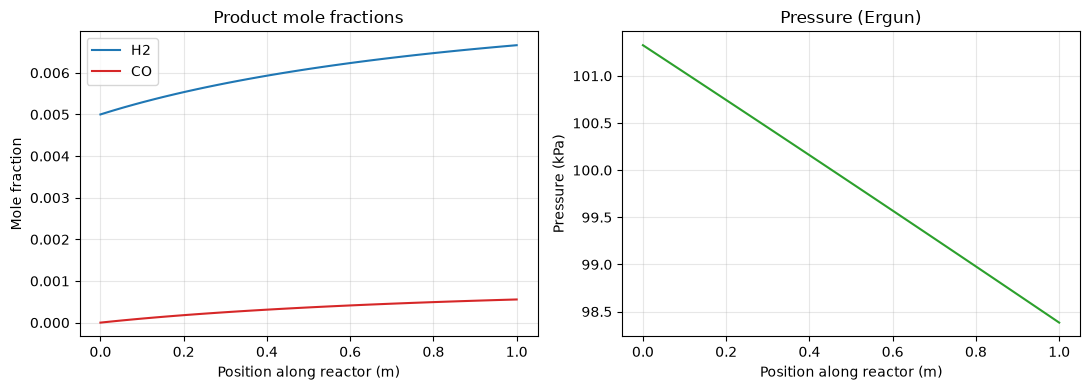

In [3]:
import matplotlib.pyplot as plt
from pfr import profiles

prof = profiles(model)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(prof["Position (m)"], prof["hydrogen"], label="H2", color="tab:blue")
ax1.plot(prof["Position (m)"], prof["carbon_monoxide"], label="CO", color="tab:red")
ax1.set_xlabel("Position along reactor (m)")
ax1.set_ylabel("Mole fraction")
ax1.set_title("Product mole fractions")
ax1.legend()
ax1.grid(alpha=0.3)
ax2.plot(prof["Position (m)"], prof["Pressure (Pa)"] / 1000, color="tab:green")
ax2.set_xlabel("Position along reactor (m)")
ax2.set_ylabel("Pressure (kPa)")
ax2.set_title("Pressure (Ergun)")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# Visualize (if needed)
model.fs.visualize("PFR Model")

'idaes.co re.util.diagnostics_tools.diagnostics_toolbox.DiagnosticsToolbox'.
Please update your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
'idaes.core.util.diagnostics_tools.diagnostics_toolbox.CONFIG'. Please update
your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
2026-11-07 10:05:57 [INFO] idaes.idaes_ui.fv.fsvis: Started visualization server
2026-11-07 10:05:57 [INFO] idaes.idaes_ui.fv.fsvis: Saving flowsheet to default file 'PFR Model.json' in current directory (c:\Users\VirajDesai\Downloads\Personal\Github\IDAES-PSE-Examples\Plug Flow Reactor)
2026-11-07 10:05:57 [WARNING] idaes.idaes_ui.fv.fsvis: Flowsheet name changed: old='PFR Model' new='PFR-Model'
Flowsheet name changed to 'PFR-Model'
2026-11-07 10:05:57 [INFO] idaes.idaes_ui.fv.fsvis: Flowsheet visualization at: http://localhost:62532/app?id=PFR-Model


VisualizeResult(store=<idaes_ui.fv.persist.FileDataStore object at 0x0000024530A32B40>, port=62532, server=<idaes_ui.fv.model_server.FlowsheetServer object at 0x000002452F09B830>, save_diagram=<bound method SaveDiagramScreenshot.save_diagram_screenshot of <idaes_ui.fv.save_diagram_screenshot.SaveDiagramScreenshot object at 0x0000024530808320>>)

## Validation against DWSIM

The DWSIM results are read directly from the solved `.dwxmz` file and compared with IDAES. The pressure drop is about 1.5 % lower in IDAES because of the viscosity mixing rule (Wilke in IDAES vs DWSIM's own method).

In [5]:
from pfr import read_dwsim_results, compare_with_dwsim

dwsim = read_dwsim_results("DWSim Plug Flow Reactor.dwxmz")
compare_with_dwsim(model, dwsim)

,IDAES,DWSIM,Difference,Error (%)
Outlet temperature (K),9.731500e+02,973.150000,0.000000e+00,0.000000
Outlet pressure (Pa),9.838295e+04,98337.436345,4.551712e+01,0.046287
Pressure drop (Pa),2.942047e+03,2987.563655,-4.551712e+01,-1.523553
Heat duty (kW),6.158526e-01,0.616220,-3.673389e-04,-0.059612
Outlet molar flow (mol/s),4.918823e+00,4.918821,1.672624e-06,0.000034
Outlet mole fraction methane,4.963904e-01,0.496391,-3.387285e-07,-0.000068
Outlet mole fraction water,4.963904e-01,0.496391,-3.387285e-07,-0.000068
Outlet mole fraction hydrogen,6.663046e-03,0.006663,5.075336e-07,0.007618
Outlet mole fraction carbon_monoxide,5.562028e-04,0.000556,1.698235e-07,0.030542
Outlet mole fraction carbon_dioxide,9.988876e-11,0.000000,9.988876e-11,NaN
